# 제4회 주조 데이터 EDA와 시각화

**목적: 데이터를 이해하고 다음 분석에서 확인할 질문을 찾습니다.** 결측 대체, 이상치 제거, 인코딩, 학습용 분할, 모델 학습은 수행하지 않습니다. `raw`는 그대로 보존하고 날짜 변환 등 분석용 표현만 복사본 `eda`에 추가합니다.

## 읽기 순서
구조 → 결측·중복 → 라벨·D → 시간 변화 → 범주별 차이 → 전체 수치형 분포 → 라벨별 분포 → 상관·산점도 → count 가설 → 특이 기록 점검.

**해석 기준:** 0·1의 합격/불합격 대응과 단위는 아직 미확인입니다. D 결측을 정상 생산이라고 단정하지 않습니다. 1449·65535 등의 값은 오류로 확정하지 않습니다. 모든 관계는 탐색 결과이며 인과관계나 모델 성능이 아닙니다.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

PROJECT_DIR = Path(r"C:/Users/KDS-30/Desktop/Projects/05_KAMP")
SOURCE = PROJECT_DIR / "previous_competition/4/경진대회용 주조 공정최적화 데이터셋.csv"
EDA_DIR = PROJECT_DIR / "previous_competition/4/outputs/eda"
FIG_DIR = EDA_DIR / "figures"
TABLE_DIR = EDA_DIR / "tables"
for folder in [FIG_DIR, TABLE_DIR]: folder.mkdir(parents=True, exist_ok=True)
TARGET = "passorfail"
ENCODING = "cp949"
RANDOM_SEED = 42
SCATTER_SAMPLE = 4000  # 산점도만 고정 시드 표본 사용. 통계와 나머지 그래프는 전체 대상 행 사용.
FOCUS_COLS = ["cast_pressure", "upper_mold_temp1", "lower_mold_temp1", "molten_temp", "biscuit_thickness", "count"]
assert SOURCE.is_file(), f"원본 경로를 확인하세요: {SOURCE}"
font_names = {f.name for f in font_manager.fontManager.ttflist}
font = next((x for x in ["Malgun Gothic", "맑은 고딕", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"] if x in font_names), None)
if font: plt.rcParams["font.family"] = font
else: print("한글 폰트가 없습니다. 한글 지원 폰트 설치 후 다시 실행하세요.")
plt.rcParams.update({"axes.unicode_minus":False,"figure.dpi":110,"savefig.dpi":140,"font.size":10})
COLORS = ["#3777A8", "#D87937"]

def show_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def show_table(frame, filename, max_rows=35):
    frame.to_csv(TABLE_DIR / filename, encoding="utf-8-sig")
    display(frame.head(max_rows))
    if len(frame)>max_rows: print(f"전체 {len(frame):,}행은 {filename}에 저장")

source_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
raw = pd.read_csv(SOURCE, encoding=ENCODING, low_memory=False)
raw_snapshot = raw.copy(deep=True)
eda = raw.copy(deep=True)
eda["_timestamp"] = pd.to_datetime(raw["registration_time"], errors="coerce")
eda["_label"] = pd.to_numeric(raw[TARGET], errors="coerce")
eda["_D"] = raw["tryshot_signal"].astype("string").eq("D").fillna(False)
eda["_month"] = eda._timestamp.dt.to_period("M").astype("string")
eda["_day"] = eda._timestamp.dt.floor("D")
eda["_hour"] = eda._timestamp.dt.hour
numeric_cols = [c for c in raw.select_dtypes(include="number") if c not in ["Unnamed: 0", TARGET, "mold_code"]]
valid = eda.loc[eda._label.isin([0,1])].copy()  # 품질 비교에만 사용하는 뷰. 원본 삭제 없음.
print("원본 크기:", raw.shape)
print("그래프 저장:", FIG_DIR)
print("주의: 같은 파일명으로 다시 실행하면 이전 EDA 산출물을 갱신합니다.")

원본 크기: (92015, 32)
그래프 저장: C:\Users\KDS-30\Desktop\Projects\05_KAMP\previous_competition\4\outputs\eda\figures
주의: 같은 파일명으로 다시 실행하면 이전 EDA 산출물을 갱신합니다.


## 1 데이터 구조와 기초 통계
한 행이 제품 하나인지 샷 하나인지는 확인이 필요합니다. 아래에서 변수 타입·고유값·결측을 확인하고, 대표값과 극단값이 얼마나 다른지 비교하세요.

In [2]:
display(raw.head())
profile = pd.DataFrame({"자료형":raw.dtypes.astype(str),"고유값수":raw.nunique(),"결측수":raw.isna().sum(),"결측률_pct":raw.isna().mean()*100})
show_table(profile, "01_column_profile.csv")
show_table(raw[numeric_cols].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T,"02_numeric_summary.csv")
print("값이 일정한 컬럼:", raw.columns[raw.nunique(dropna=True).le(1)].tolist())
print("기간:", eda._timestamp.min(), "~", eda._timestamp.max())
print("관측 날짜 수:", eda._day.nunique())
for c in ["line","name","mold_name","working","emergency_stop","tryshot_signal","mold_code","heating_furnace"]:
    print(c, raw[c].value_counts(dropna=False).to_dict())

,Unnamed: 0,line,name,mold_name,time,date,count,working,emergency_stop,molten_temp,...,lower_mold_temp3,sleeve_temperature,physical_strength,Coolant_temperature,EMS_operation_time,registration_time,passorfail,tryshot_signal,mold_code,heating_furnace
0,0,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-02,16:45:06,258,가동,ON,731.0,...,1449.0,550.0,700.0,34.0,23,2019-01-02 16:45:06,0.0,NaN,8722,NaN
1,1,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-02,16:45:08,243,가동,ON,720.0,...,NaN,481.0,0.0,30.0,25,2019-01-02 16:45:08,0.0,NaN,8412,B
2,2,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-02,16:45:58,244,가동,ON,721.0,...,NaN,481.0,0.0,30.0,25,2019-01-02 16:45:58,0.0,NaN,8412,B
3,3,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-02,16:48:03,245,가동,ON,721.0,...,NaN,483.0,0.0,30.0,25,2019-01-02 16:48:03,0.0,NaN,8412,B
4,4,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-02,16:50:08,246,가동,ON,721.0,...,NaN,486.0,0.0,30.0,25,2019-01-02 16:50:08,0.0,NaN,8412,B


,자료형,고유값수,결측수,결측률_pct
Unnamed: 0,int64,92015,0,0.000000
line,str,1,0,0.000000
name,str,1,0,0.000000
mold_name,str,1,0,0.000000
time,str,85,0,0.000000
date,str,54640,0,0.000000
count,int64,334,0,0.000000
working,str,2,1,0.001087
emergency_stop,str,1,1,0.001087
molten_temp,float64,113,2261,2.457208


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
count,92015.0,148.510895,87.969953,1.0,3.00,15.0,72.0,146.0,222.0,290.0,312.0,334.0
molten_temp,89754.0,718.618513,51.728659,0.0,683.00,706.0,713.0,728.0,730.0,732.0,733.0,735.0
facility_operation_cycleTime,92015.0,121.555007,12.116145,0.0,113.00,115.0,117.0,119.0,122.0,134.0,198.0,457.0
production_cycletime,92015.0,122.514525,13.595314,0.0,85.00,117.0,119.0,121.0,123.0,132.0,203.0,485.0
low_section_speed,92014.0,110.794999,305.181962,0.0,99.00,100.0,110.0,110.0,110.0,115.0,140.0,65535.0
high_section_speed,92014.0,112.624959,10.759272,0.0,101.00,102.0,112.0,112.0,112.0,117.0,144.0,388.0
molten_volume,46885.0,154.976624,485.640901,0.0,9.00,27.0,49.0,67.0,85.0,102.0,2767.0,2767.0
cast_pressure,92014.0,324.554535,27.327683,41.0,156.00,315.0,329.0,330.0,331.0,333.0,334.0,348.0
biscuit_thickness,92014.0,50.666486,17.925620,0.0,38.00,42.0,47.0,50.0,53.0,56.0,56.0,422.0
upper_mold_temp1,92014.0,186.208870,46.041322,18.0,87.00,102.0,163.0,194.0,222.0,241.0,279.0,1449.0


값이 일정한 컬럼: ['line', 'name', 'mold_name', 'emergency_stop', 'tryshot_signal']
기간: 2019-01-02 16:45:06 ~ 2019-03-31 23:59:48
관측 날짜 수: 85
line {'전자교반 3라인 2호기': 92015}
name {'TM Carrier RH': 92015}
mold_name {'TM Carrier RH-Semi-Solid DIE-06': 92015}
working {'가동': 91963, '정지': 51, nan: 1}
emergency_stop {'ON': 92014, nan: 1}
tryshot_signal {nan: 90096, 'D': 1919}
mold_code {8917: 31112, 8412: 21471, 8722: 20049, 8573: 9596, 8413: 6034, 8600: 2960, 8576: 793}
heating_furnace {nan: 49146, 'A': 21443, 'B': 21426}


## 2 결측과 중복
결측률이 높은 컬럼을 곧바로 삭제하지 않습니다. 금형 코드별 결측 패턴이 다르면 수집 구조 차이일 수 있습니다. 시각 중복도 서로 다른 기록일 수 있으므로 진단만 수행합니다.

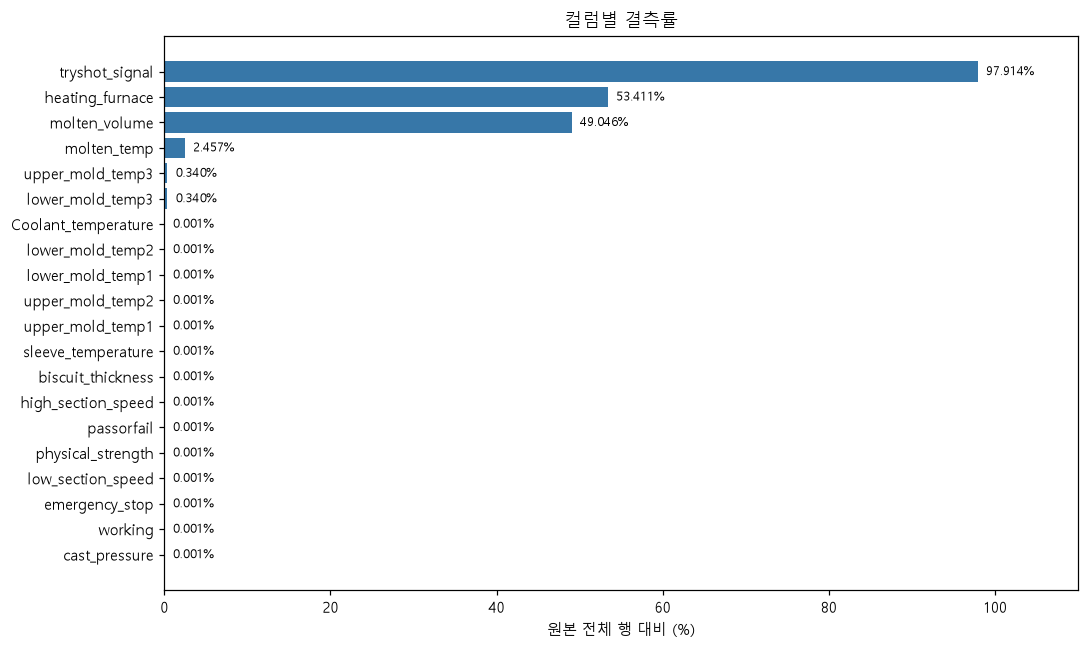

,molten_volume,molten_temp,heating_furnace,upper_mold_temp3,lower_mold_temp3
mold_code,,,,,
8412,80.676261,10.530483,29.854222,1.453123,1.453123
8413,0.000000,0.000000,100.000000,0.000000,0.000000
8573,100.000000,0.000000,0.000000,0.000000,0.000000
8576,100.000000,0.000000,0.000000,0.000000,0.000000
8600,0.000000,0.000000,100.000000,0.000000,0.000000
8722,0.000000,0.000000,100.000000,0.004988,0.004988
8917,55.988043,0.000000,44.011957,0.000000,0.000000


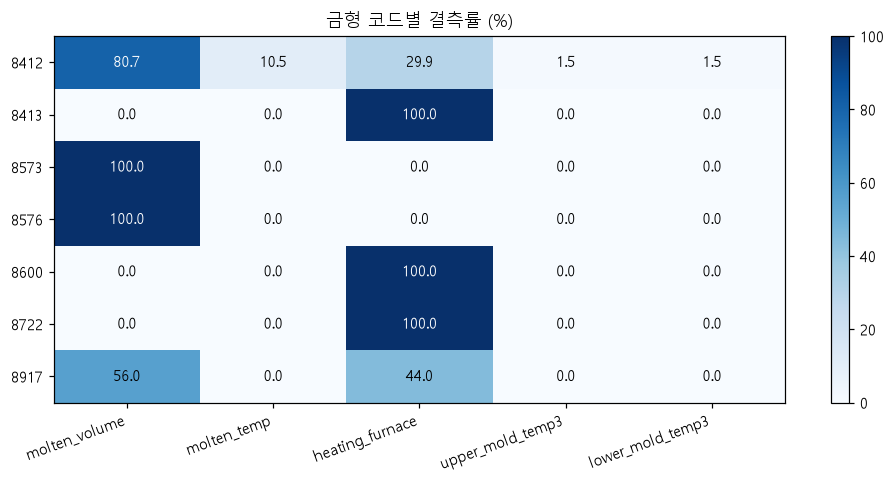

,건수
날짜 변환 실패,0
날짜 결합값 변환 실패,0
시간 표현 불일치,0
인덱스 제외 완전 중복,0
중복 시각의 추가 행,293
시각과 금형 코드 중복 추가 행,10


,Unnamed: 0,line,name,mold_name,time,date,count,working,emergency_stop,molten_temp,...,lower_mold_temp3,sleeve_temperature,physical_strength,Coolant_temperature,EMS_operation_time,registration_time,passorfail,tryshot_signal,mold_code,heating_furnace
47287,47287,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,08:06:54,5,가동,ON,728.0,...,1449.0,356.0,706.0,26.0,23,2019-02-21 08:06:54,1.0,D,8917,NaN
47288,47288,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,08:06:54,2,가동,ON,729.0,...,1449.0,490.0,674.0,22.0,23,2019-02-21 08:06:54,1.0,D,8917,NaN
47400,47400,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,09:35:44,48,가동,ON,713.0,...,1449.0,424.0,704.0,30.0,23,2019-02-21 09:35:44,0.0,NaN,8917,NaN
47401,47401,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,09:35:44,44,가동,ON,729.0,...,1449.0,536.0,667.0,26.0,23,2019-02-21 09:35:44,0.0,NaN,8917,NaN
47457,47457,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,10:17:21,69,가동,ON,728.0,...,1449.0,429.0,702.0,31.0,23,2019-02-21 10:17:21,0.0,NaN,8917,NaN
47458,47458,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,10:17:21,64,가동,ON,731.0,...,1449.0,533.0,665.0,28.0,23,2019-02-21 10:17:21,0.0,NaN,8917,NaN
47709,47709,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,13:17:19,151,가동,ON,729.0,...,1449.0,442.0,703.0,30.0,23,2019-02-21 13:17:19,0.0,NaN,8917,NaN
47710,47710,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,13:17:19,146,가동,ON,729.0,...,1449.0,534.0,672.0,29.0,23,2019-02-21 13:17:19,0.0,NaN,8917,NaN
47766,47766,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,13:56:43,170,가동,ON,728.0,...,1449.0,434.0,700.0,31.0,23,2019-02-21 13:56:43,0.0,NaN,8917,NaN
47767,47767,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-21,13:56:43,165,가동,ON,708.0,...,1449.0,529.0,672.0,29.0,23,2019-02-21 13:56:43,0.0,NaN,8917,NaN


In [3]:
missing = (raw.isna().mean()*100).sort_values()
missing = missing[missing.gt(0)]
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(missing.index, missing, color=COLORS[0])
for i,v in enumerate(missing): ax.text(v+1,i,f"{v:.3f}%",va="center",fontsize=8)
ax.set_xlim(0,110);ax.set_xlabel("원본 전체 행 대비 (%)");ax.set_title("컬럼별 결측률")
show_plot(fig,"01_missing_rates.png")

cols_missing = [c for c in ["molten_volume","molten_temp","heating_furnace","upper_mold_temp3","lower_mold_temp3"] if c in raw]
by_mold_missing = raw[cols_missing].isna().groupby(raw.mold_code).mean()*100
show_table(by_mold_missing,"03_missing_by_mold.csv")
fig,ax=plt.subplots(figsize=(9,4.5))
im=ax.imshow(by_mold_missing,cmap="Blues",vmin=0,vmax=100,aspect="auto")
ax.set_xticks(range(len(cols_missing)),cols_missing,rotation=20,ha="right")
ax.set_yticks(range(len(by_mold_missing)),by_mold_missing.index.astype(str))
for i in range(len(by_mold_missing)):
    for j in range(len(cols_missing)):
        value=by_mold_missing.iloc[i,j]
        ax.text(j,i,f"{value:.1f}",ha="center",va="center",color="white" if value>60 else "black")
ax.set_title("금형 코드별 결측률 (%)");fig.colorbar(im,ax=ax)
show_plot(fig,"02_missing_by_mold.png")

combined=pd.to_datetime(raw.time.astype("string")+" "+raw.date.astype("string"),errors="coerce")
dup_cols=[c for c in raw if c!="Unnamed: 0"]
checks=pd.Series({"날짜 변환 실패":int(eda._timestamp.isna().sum()),"날짜 결합값 변환 실패":int(combined.isna().sum()),"시간 표현 불일치":int((combined.notna() & eda._timestamp.notna() & combined.ne(eda._timestamp)).sum()),"인덱스 제외 완전 중복":int(raw.duplicated(dup_cols).sum()),"중복 시각의 추가 행":int(raw.duplicated("registration_time").sum()),"시각과 금형 코드 중복 추가 행":int(raw.duplicated(["registration_time","mold_code"]).sum())},name="건수")
show_table(checks.to_frame(),"04_duplicate_time_checks.csv")
display(raw.loc[raw.duplicated(["registration_time","mold_code"],keep=False)].head(12))

## 3 라벨 분포와 D 신호
유효 라벨만 분모로 사용합니다. 라벨 결측은 전체 건수 표에 별도 표시합니다. D 그룹의 편중은 예측 가능성뿐 아니라 판정 규칙·기록 시점 차이일 수도 있습니다.

,건수
passorfail,
0.0,87998
1.0,4016
NaN,1


_label,0,1
D 아님 또는 결측,87998,2097
D,0,1919


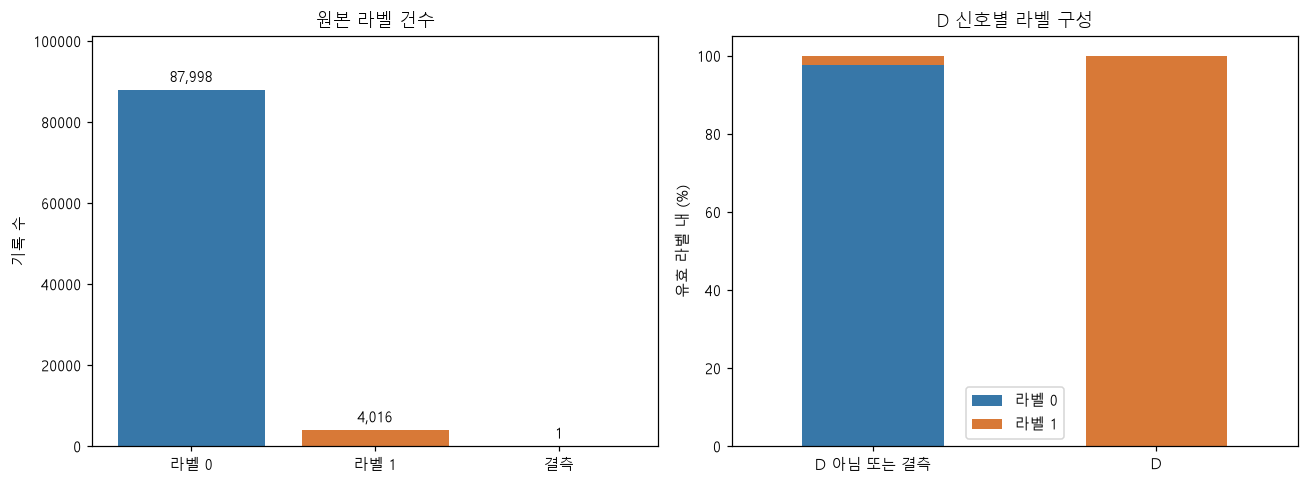

In [4]:
label_counts=raw[TARGET].value_counts(dropna=False).rename("건수").to_frame()
show_table(label_counts,"05_label_counts.csv")
tab=pd.crosstab(valid._D,valid._label).reindex(index=[False,True],columns=[0,1],fill_value=0)
tab.index=["D 아님 또는 결측","D"]
show_table(tab,"06_D_label_counts.csv")
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
counts=[int(eda._label.eq(0).sum()),int(eda._label.eq(1).sum()),int(raw[TARGET].isna().sum())]
bars=axes[0].bar(["라벨 0","라벨 1","결측"],counts,color=COLORS+["#AAAAAA"])
axes[0].bar_label(bars,labels=[f"{n:,}" for n in counts],padding=3);axes[0].set_ylim(0,max(counts)*1.15)
axes[0].set_title("원본 라벨 건수");axes[0].set_ylabel("기록 수")
rate=tab.div(tab.sum(axis=1).replace(0,np.nan),axis=0)*100
rate.plot.bar(stacked=True,ax=axes[1],color=COLORS,rot=0)
axes[1].set_title("D 신호별 라벨 구성");axes[1].set_ylabel("유효 라벨 내 (%)")
axes[1].legend(["라벨 0","라벨 1"])
show_plot(fig,"03_labels_and_D.png")

## 4 시간에 따른 라벨과 생산 기록 변화
월별 비율과 표본 수를 함께 확인합니다. 일별 집계에서 기록 수가 작은 날의 비율은 흔들릴 수 있습니다. 여기서 기록 수는 생산량으로 확정되지 않았습니다.

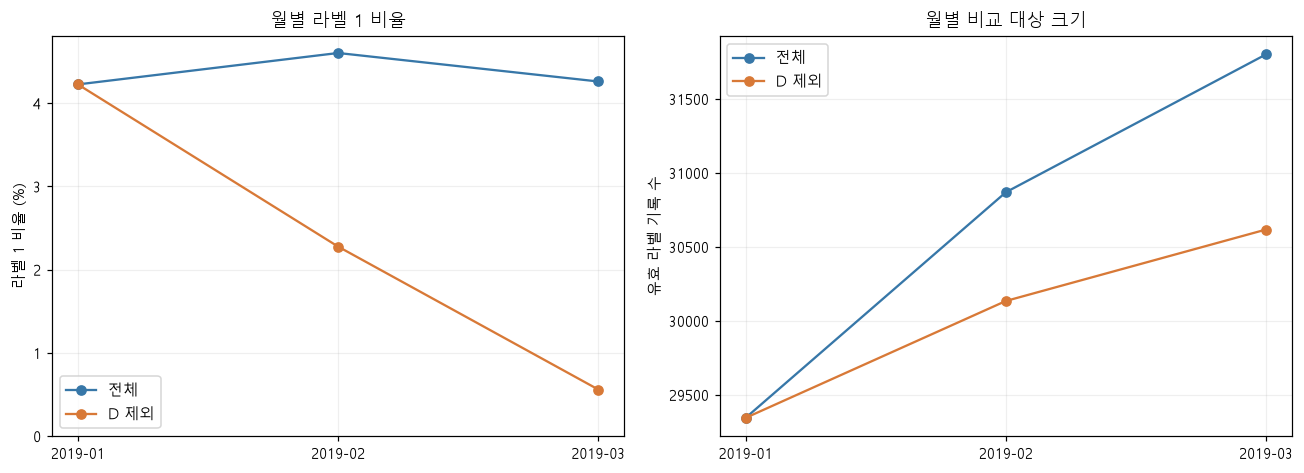

,_month,기록수,라벨1수,라벨1비율,비교대상
0,2019-01,29344,1240.0,0.042257,전체
1,2019-02,30869,1421.0,0.046033,전체
2,2019-03,31801,1355.0,0.042609,전체
3,2019-01,29344,1240.0,0.042257,D 제외
4,2019-02,30134,686.0,0.022765,D 제외
5,2019-03,30617,171.0,0.005585,D 제외


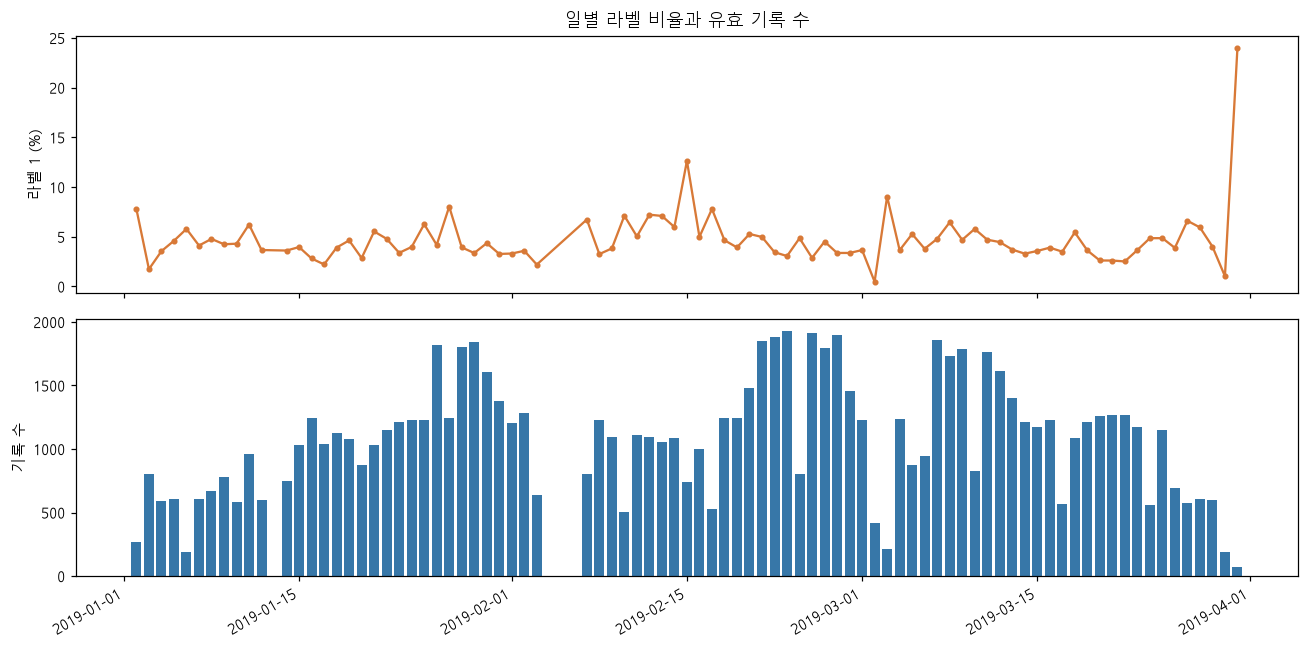

,기록수,라벨1수,라벨1비율
_day,,,
2019-01-02,270,21.0,0.077778
2019-01-03,804,14.0,0.017413
2019-01-04,591,21.0,0.035533
2019-01-05,609,28.0,0.045977
2019-01-06,190,11.0,0.057895
2019-01-07,607,25.0,0.041186
2019-01-08,669,32.0,0.047833
2019-01-09,777,33.0,0.042471
2019-01-10,581,25.0,0.043029


전체 85행은 08_daily_labels.csv에 저장


In [5]:
monthly_tables=[]
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for label,subset,color in [("전체",valid,COLORS[0]),("D 제외",valid.loc[~valid._D],COLORS[1])]:
    g=subset.groupby("_month")._label.agg(기록수="size",라벨1수="sum",라벨1비율="mean")
    g["비교대상"]=label;monthly_tables.append(g.reset_index())
    axes[0].plot(g.index.astype(str),g.라벨1비율*100,marker="o",label=label,color=color)
    axes[1].plot(g.index.astype(str),g.기록수,marker="o",label=label,color=color)
axes[0].set_ylabel("라벨 1 비율 (%)");axes[0].set_ylim(bottom=0);axes[0].set_title("월별 라벨 1 비율")
axes[1].set_ylabel("유효 라벨 기록 수");axes[1].set_title("월별 비교 대상 크기")
for ax in axes:ax.legend();ax.grid(alpha=.2)
show_plot(fig,"04_monthly_labels.png")
show_table(pd.concat(monthly_tables,ignore_index=True),"07_monthly_labels.csv")

daily=valid.groupby("_day")._label.agg(기록수="size",라벨1수="sum",라벨1비율="mean")
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
axes[0].plot(daily.index,daily.라벨1비율*100,color=COLORS[1],marker=".")
axes[0].set_ylabel("라벨 1 (%)");axes[0].set_title("일별 라벨 비율과 유효 기록 수")
axes[1].bar(daily.index,daily.기록수,color=COLORS[0]);axes[1].set_ylabel("기록 수")
fig.autofmt_xdate();show_plot(fig,"05_daily_labels.png")
show_table(daily,"08_daily_labels.csv",10)

## 5 범주별 라벨 차이
금형 코드·가열로·가동 상태별 비율과 건수를 함께 봅니다. 이는 보정되지 않은 비교입니다. 월별 생산 구성 등이 달라 생긴 차이일 수 있고, 가동 상태가 사후 기록이면 원인으로 해석할 수 없습니다.

,기록수,라벨1수,라벨1비율
mold_code,,,
8412,21471,744.0,0.034651
8413,6034,226.0,0.037454
8573,9596,420.0,0.043768
8576,793,40.0,0.050441
8600,2960,150.0,0.050676
8722,20048,1088.0,0.054270
8917,31112,1348.0,0.043327


,기록수,라벨1수,라벨1비율
heating_furnace,,,
(결측),49145,2228.0,0.045335
A,21443,816.0,0.038054
B,21426,972.0,0.045365


,기록수,라벨1수,라벨1비율
working,,,
가동,91963,3967.0,0.043137
정지,51,49.0,0.960784


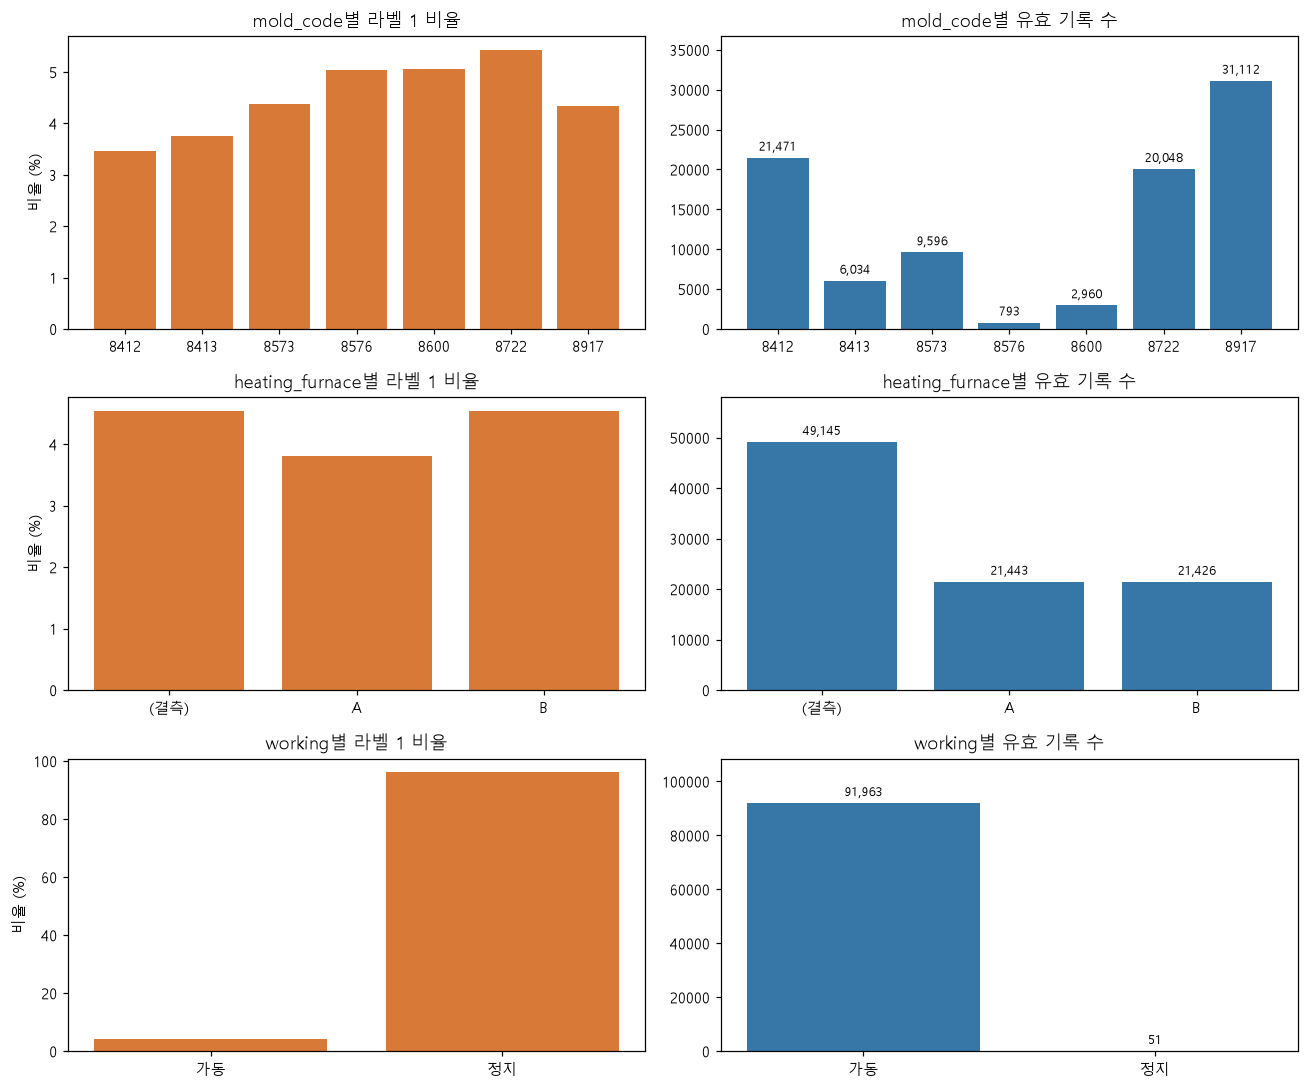

In [6]:
fig,axes=plt.subplots(3,2,figsize=(12,10))
for row,col in enumerate(["mold_code","heating_furnace","working"]):
    group=valid.groupby(valid[col].astype("string").fillna("(결측)"))._label.agg(기록수="size",라벨1수="sum",라벨1비율="mean")
    show_table(group,f"09_group_{col}.csv")
    axes[row,0].bar(group.index,group.라벨1비율*100,color=COLORS[1])
    axes[row,0].set_title(f"{col}별 라벨 1 비율");axes[row,0].set_ylabel("비율 (%)")
    bars=axes[row,1].bar(group.index,group.기록수,color=COLORS[0])
    axes[row,1].bar_label(bars,labels=[f"{v:,}" for v in group.기록수],fontsize=8,padding=3)
    axes[row,1].set_ylim(0,group.기록수.max()*1.18);axes[row,1].set_title(f"{col}별 유효 기록 수")
show_plot(fig,"06_categorical_comparison.png")

## 6 모든 수치형 공정 변수의 분포
원본의 결측과 무한대는 그래프 계산에서만 제외합니다. 인덱스·라벨·금형 코드는 수치형 공정 변수에서 제외했습니다. 전체 범위 히스토그램과 1~99백분위 확대 화면을 모두 제공합니다. 확대는 **표시만 제한**하며 원본을 정제하지 않습니다. 각 패널에서 표시되지 않는 유효값 수를 확인하세요.

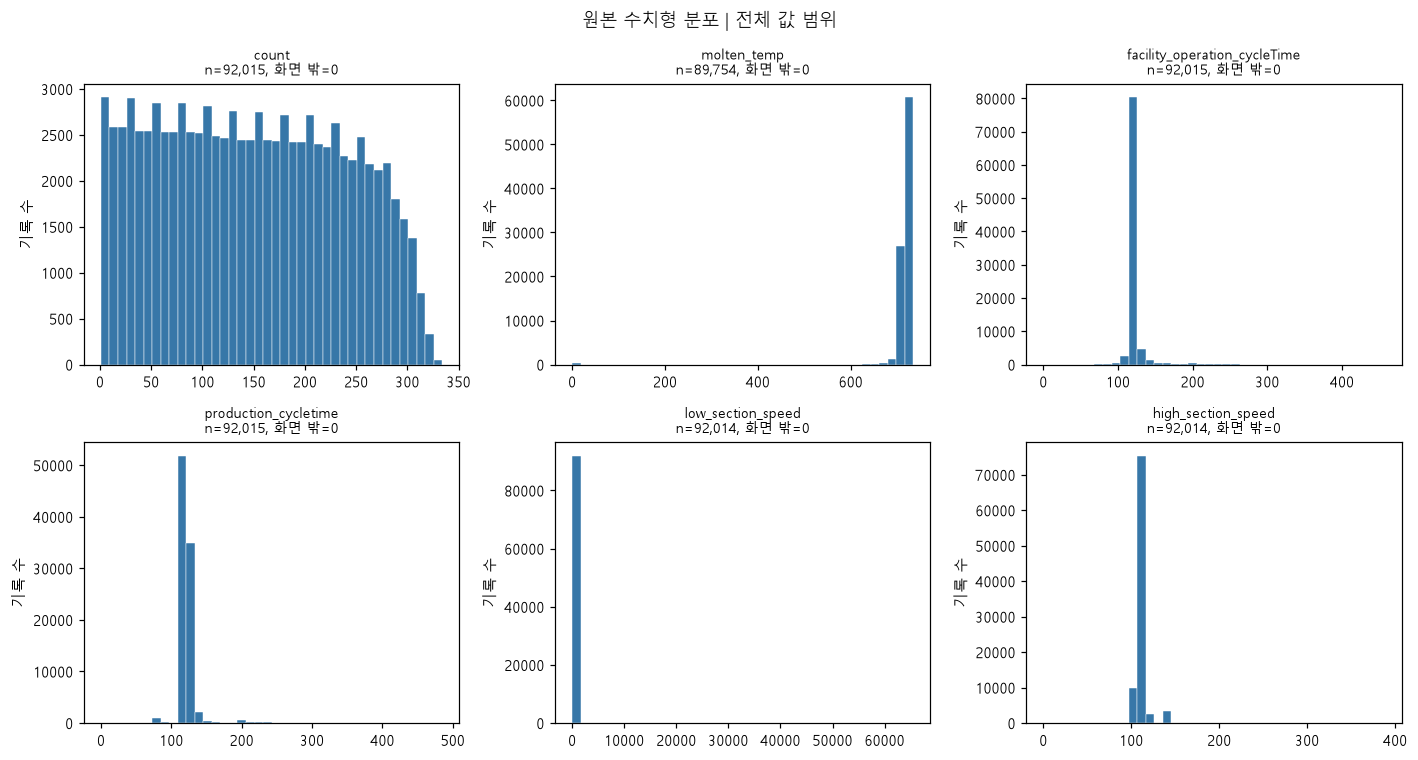

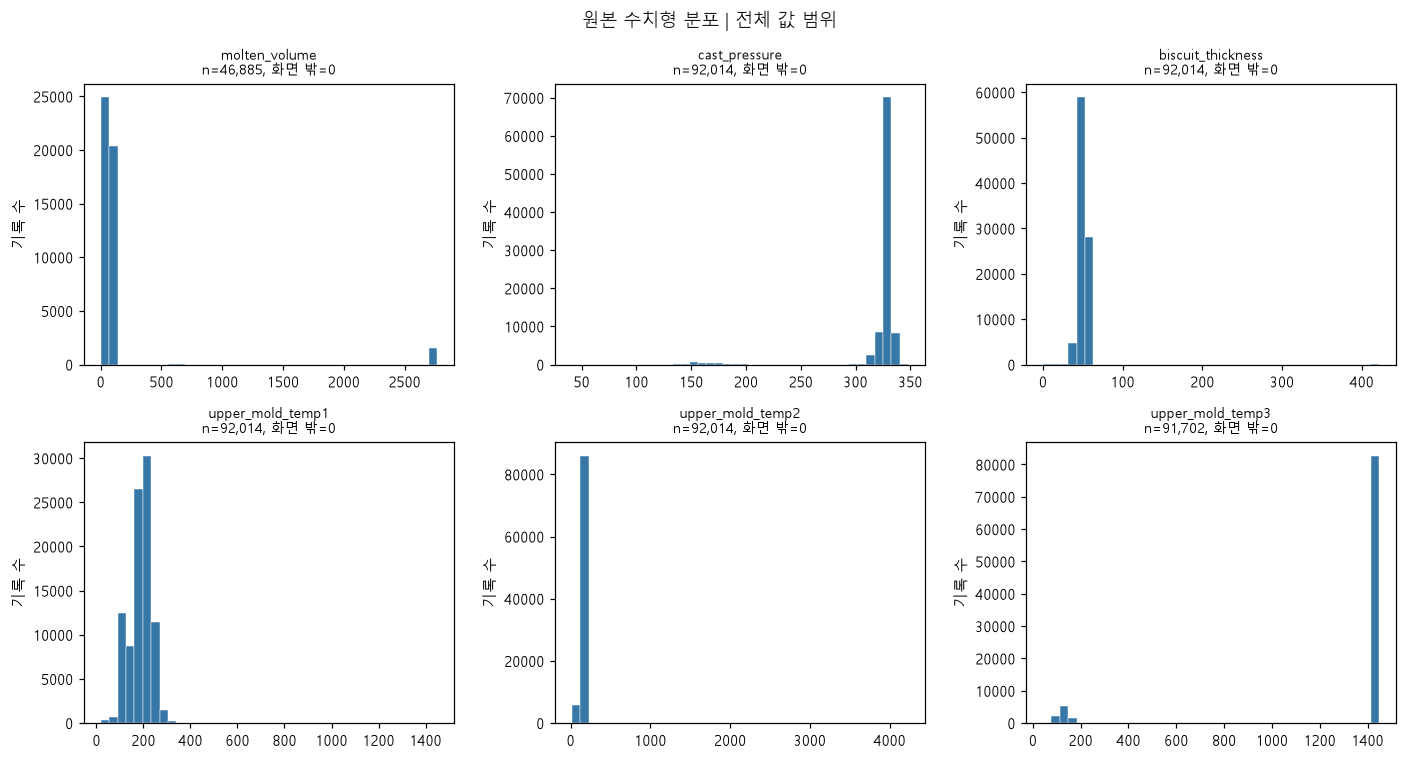

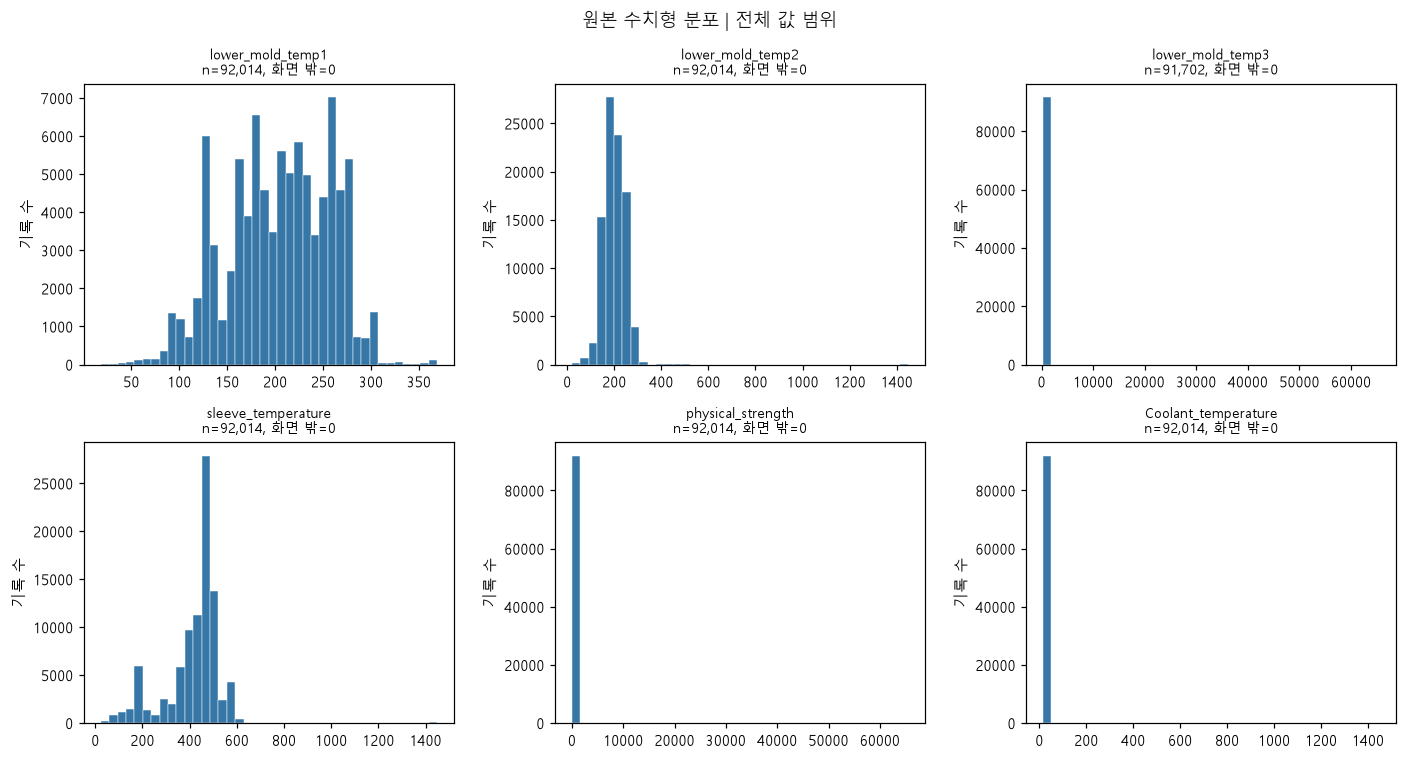

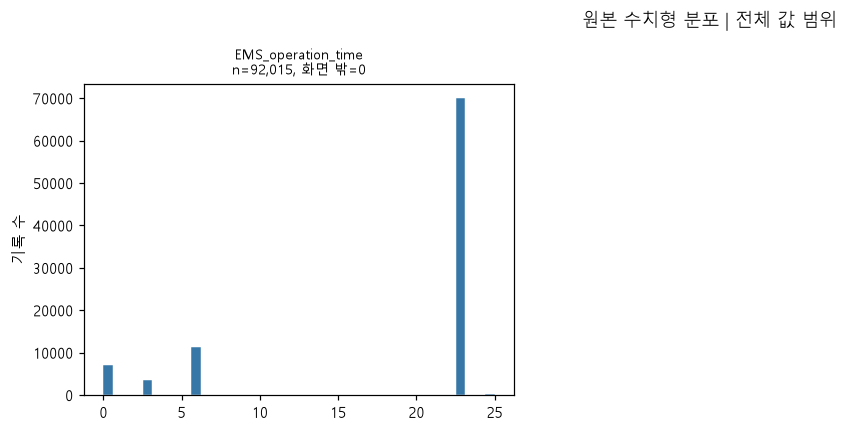

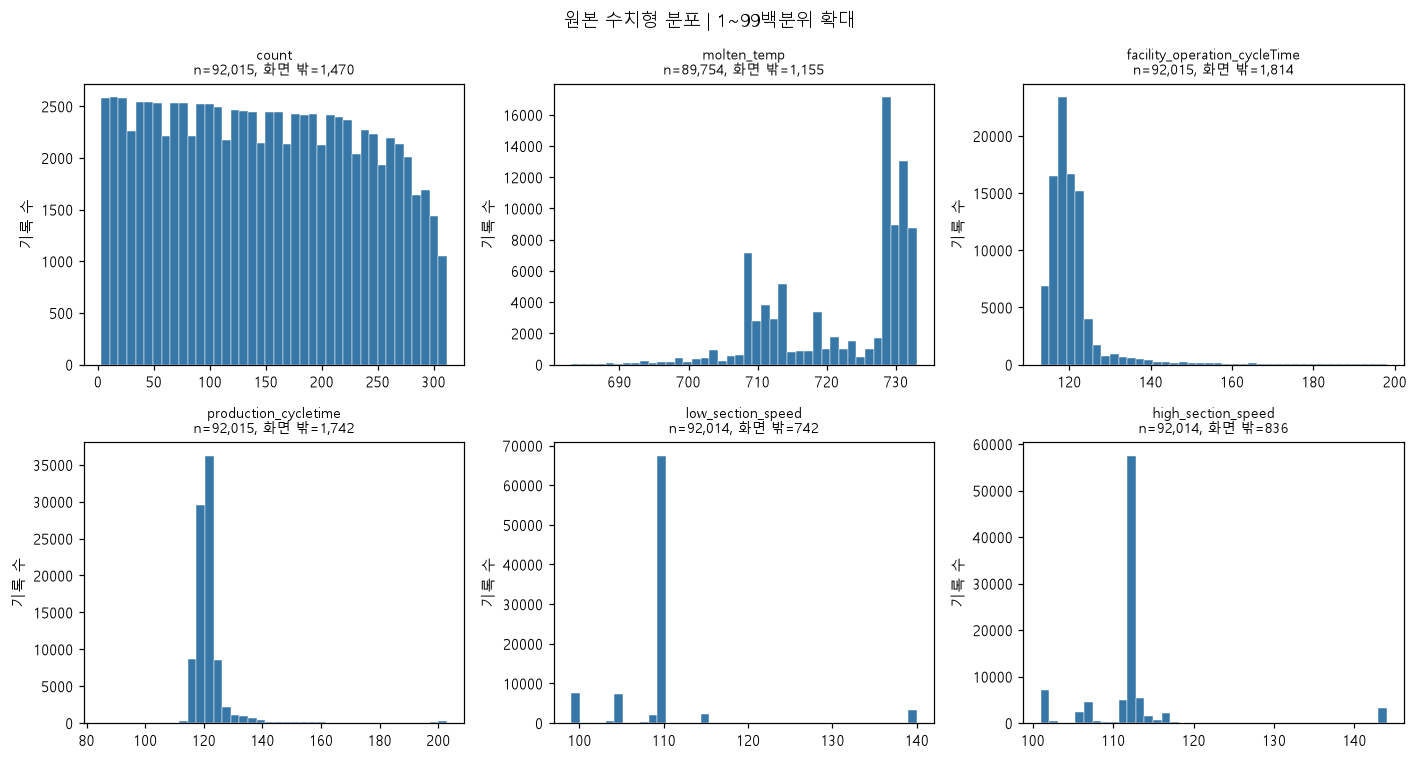

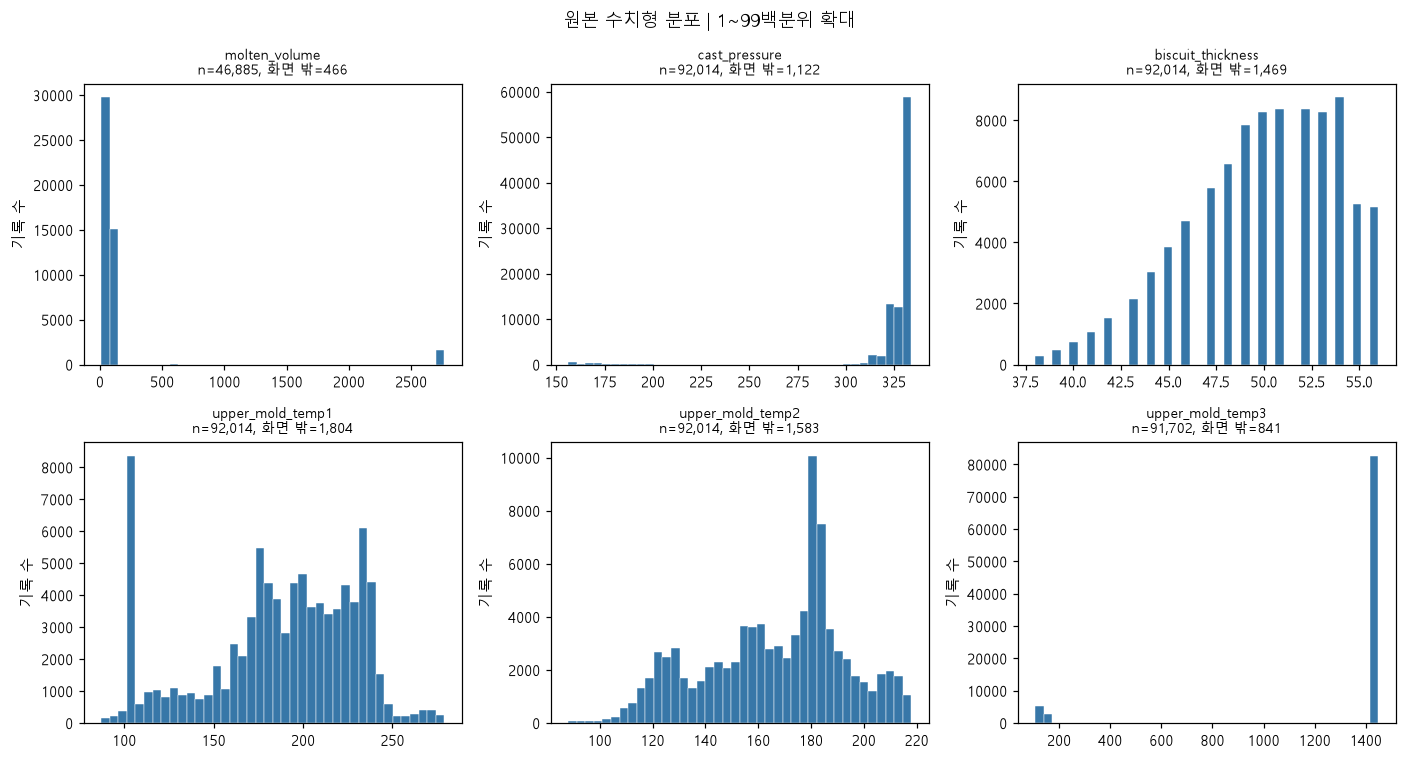

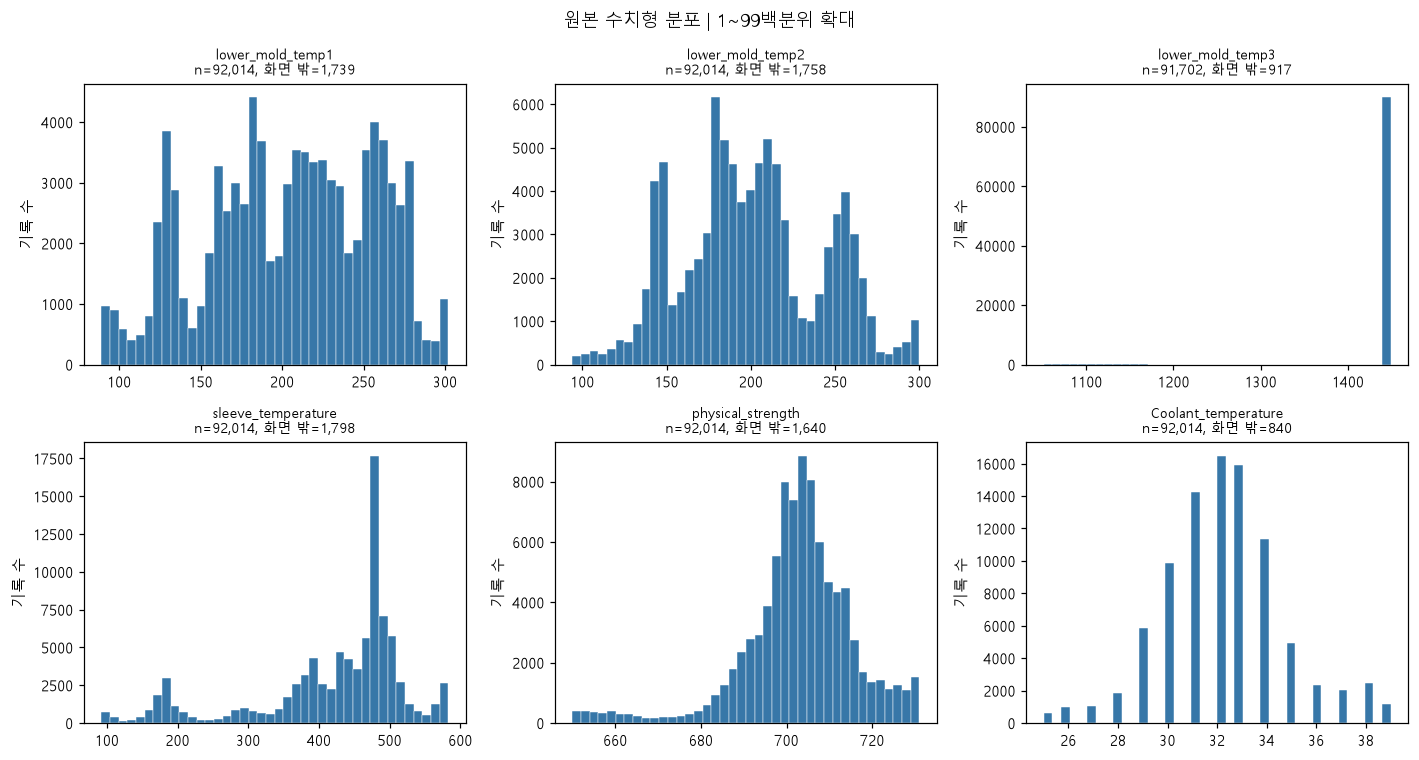

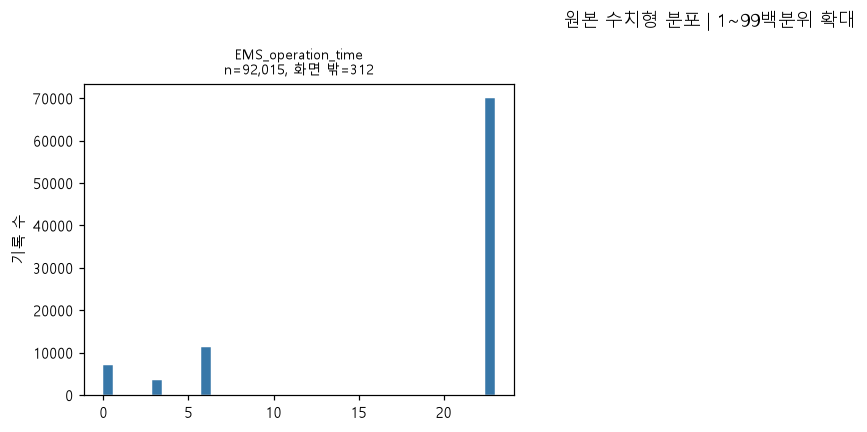

In [7]:
for zoom in [False,True]:
    for start in range(0,len(numeric_cols),6):
        cols=numeric_cols[start:start+6]
        fig,axes=plt.subplots(2,3,figsize=(13,7))
        for ax,col in zip(axes.flat,cols):
            vals=pd.to_numeric(raw[col],errors="coerce").replace([np.inf,-np.inf],np.nan).dropna()
            limits=None;hidden=0
            if zoom and len(vals):
                lo,hi=vals.quantile([.01,.99])
                if hi>lo:
                    limits=(lo,hi);hidden=int(((vals<lo)|(vals>hi)).sum())
            ax.hist(vals,bins=40,range=limits,color=COLORS[0],edgecolor="white",linewidth=.3)
            ax.set_title(f"{col}\nn={len(vals):,}, 화면 밖={hidden:,}",fontsize=9)
            ax.set_ylabel("기록 수")
        for ax in list(axes.flat)[len(cols):]:ax.set_visible(False)
        label="1~99백분위 확대" if zoom else "전체 값 범위"
        fig.suptitle(f"원본 수치형 분포 | {label}")
        show_plot(fig,f"07_hist_{'zoom' if zoom else 'full'}_{start//6+1}.png")

## 7 라벨별 주요 변수 분포
전체와 D 제외를 나란히 비교할 수 있도록 각각 그립니다. 표는 유효값 개수·평균·중앙값을 담습니다. 박스플롯은 극단 관측점만 숨기며 수염까지는 모두 표시합니다. 앞의 히스토그램으로 전체 범위도 확인하세요.

cast_pressure                               upper_mold_temp1  \
               count        mean median        std            count   
_label                                                                
0.0            87998  328.970863  330.0   5.078062            87998   
1.0             4016  227.784612  172.0  82.190664             4016   

                                     lower_mold_temp1              ...  \
              mean median        std            count        mean  ...   
_label                                                             ...   
0.0     188.461545  195.0  43.984155            87998  206.405111  ...   
1.0     136.848606  135.0  60.258220             4016  145.941733  ...   

       molten_temp            biscuit_thickness                               \
            median        std             count       mean median        std   
_label                                                                         
0.0          728.0  51.473626             87998  49.948908   50.0   4.078436   
1.0          729.0  56.993707              4016  66.389940   49.0  82.102593   

        count                                
        count        mean median        std  
_label                                       
0.0     87998  151.858997  150.0  86.284309  
1.0      4016   75.114791   18.0  92.422343  

[2 rows x 24 columns]

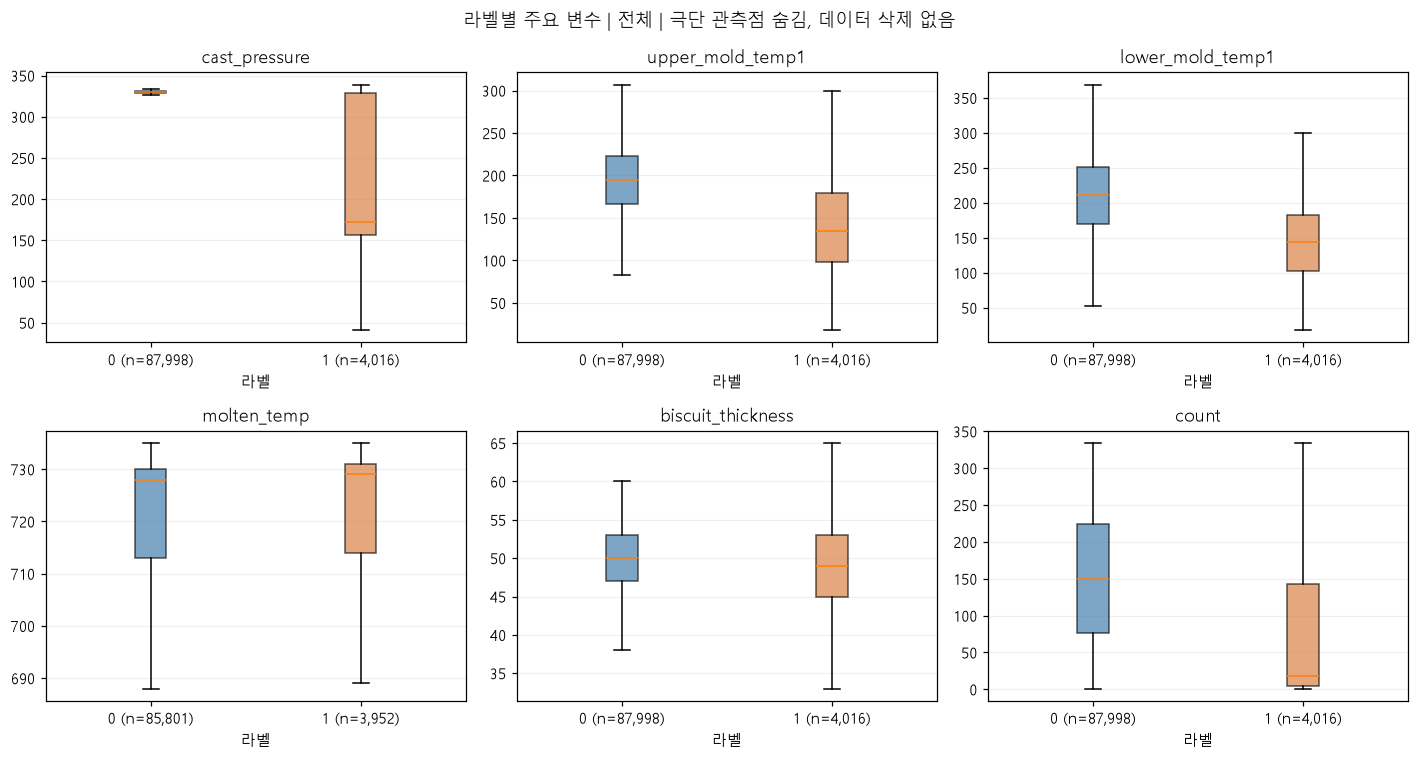

cast_pressure                               upper_mold_temp1  \
               count        mean median        std            count   
_label                                                                
0.0            87998  328.970863  330.0   5.078062            87998   
1.0             2097  223.746781  173.0  80.235390             2097   

                                     lower_mold_temp1              ...  \
              mean median        std            count        mean  ...   
_label                                                             ...   
0.0     188.461545  195.0  43.984155            87998  206.405111  ...   
1.0     140.749165  137.0  64.834294             2097  153.327611  ...   

       molten_temp            biscuit_thickness                               \
            median        std             count       mean median        std   
_label                                                                         
0.0          728.0  51.473626             87998  49.948908   50.0   4.078436   
1.0          718.0  68.144873              2097  65.731044   49.0  82.022387   

        count                                
        count        mean median        std  
_label                                       
0.0     87998  151.858997  150.0  86.284309  
1.0      2097   86.666190   49.0  93.492413  

[2 rows x 24 columns]

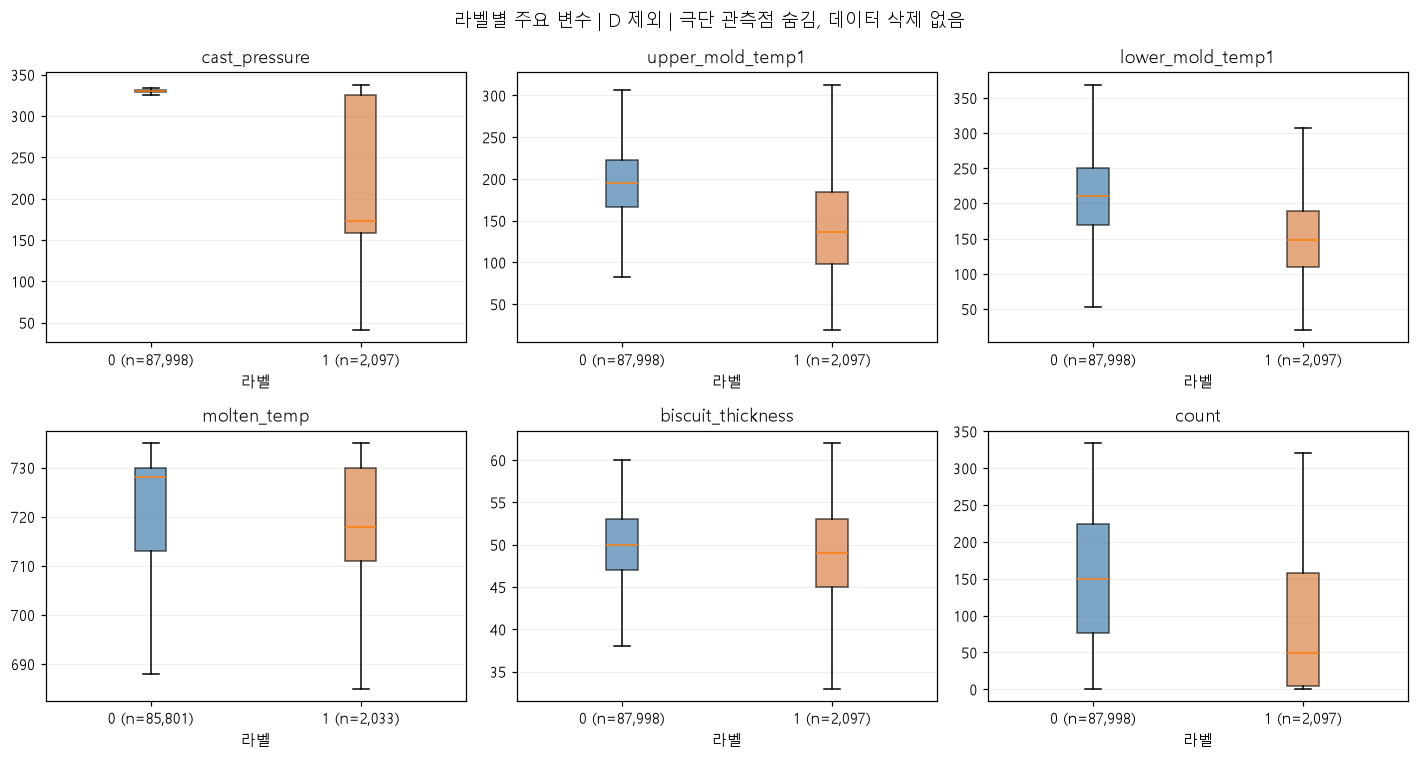

In [8]:
for group_name,subset in [("전체",valid),("D 제외",valid.loc[~valid._D])]:
    summary=subset.groupby("_label")[FOCUS_COLS].agg(["count","mean","median","std"])
    show_table(summary,f"10_label_summary_{'all' if group_name=='전체' else 'nonD'}.csv")
    fig,axes=plt.subplots(2,3,figsize=(13,7))
    for ax,col in zip(axes.flat,FOCUS_COLS):
        values=[pd.to_numeric(subset.loc[subset._label.eq(k),col],errors="coerce").replace([np.inf,-np.inf],np.nan).dropna().to_numpy() for k in [0,1]]
        bp=ax.boxplot(values,tick_labels=[f"0 (n={len(values[0]):,})",f"1 (n={len(values[1]):,})"],showfliers=False,patch_artist=True)
        for patch,color in zip(bp["boxes"],COLORS):patch.set_facecolor(color);patch.set_alpha(.65)
        ax.set_title(col);ax.set_xlabel("라벨");ax.grid(axis="y",alpha=.2)
    fig.suptitle(f"라벨별 주요 변수 | {group_name} | 극단 관측점 숨김, 데이터 삭제 없음")
    show_plot(fig,f"08_box_{'all' if group_name=='전체' else 'nonD'}.png")

## 8 변수 간 상관관계
전체 원본 공정 변수의 Spearman 순위 상관을 두 변수 모두 유효한 행에서 계산합니다. 컬럼별 결측이 달라 쌍마다 표본 수가 다릅니다. 쌍별 유효 표본 수도 저장합니다. 오류 의심값을 보존한 결과이므로 관계를 확정하지 않습니다.

,count,molten_temp,facility_operation_cycleTime,production_cycletime,low_section_speed,high_section_speed,molten_volume,cast_pressure,biscuit_thickness,upper_mold_temp1,upper_mold_temp2,upper_mold_temp3,lower_mold_temp1,lower_mold_temp2,lower_mold_temp3,sleeve_temperature,physical_strength,Coolant_temperature,EMS_operation_time
count,1.000000,-0.006251,-0.009069,0.019539,0.034367,-0.007915,0.052028,0.033738,-0.037948,0.081670,0.200863,0.026098,0.133527,0.110860,0.011970,0.022944,0.025988,0.266069,0.015729
molten_temp,-0.006251,1.000000,0.002971,-0.084763,-0.243130,-0.249326,-0.496127,-0.095126,0.213508,0.337873,0.027759,-0.003758,-0.125094,0.289077,-0.020776,-0.383343,0.218804,0.007598,-0.481666
facility_operation_cycleTime,-0.009069,0.002971,1.000000,0.595558,-0.136738,-0.114090,-0.033079,-0.010271,-0.031023,0.058362,0.050044,-0.190578,-0.044383,0.169782,-0.067995,0.008813,-0.089773,-0.049971,0.087840
production_cycletime,0.019539,-0.084763,0.595558,1.000000,-0.073196,-0.067468,-0.000071,-0.012958,-0.123342,0.050404,0.040977,-0.188272,-0.026787,0.154520,-0.076764,0.144772,-0.226368,-0.067247,0.244906
low_section_speed,0.034367,-0.243130,-0.136738,-0.073196,1.000000,0.774271,0.103538,0.189575,0.088240,0.002651,0.048722,-0.076453,-0.032485,-0.054589,0.226345,0.003580,0.062264,0.012831,0.054216
high_section_speed,-0.007915,-0.249326,-0.114090,-0.067468,0.774271,1.000000,0.100914,0.124016,0.050762,-0.021607,0.031781,-0.151747,-0.109147,-0.081231,0.185184,0.047531,0.034521,-0.006823,0.087132
molten_volume,0.052028,-0.496127,-0.033079,-0.000071,0.103538,0.100914,1.000000,0.067699,-0.399568,-0.075477,-0.011404,NaN,-0.106509,-0.037566,-0.022773,-0.046071,-0.061992,-0.003731,-0.006896
cast_pressure,0.033738,-0.095126,-0.010271,-0.012958,0.189575,0.124016,0.067699,1.000000,0.086841,-0.129326,-0.039531,-0.110493,-0.055898,-0.089034,0.166697,0.171986,0.231195,0.171205,-0.102762
biscuit_thickness,-0.037948,0.213508,-0.031023,-0.123342,0.088240,0.050762,-0.399568,0.086841,1.000000,0.070549,0.086374,-0.258791,-0.215394,-0.041028,0.081383,-0.086170,0.314086,-0.001423,-0.281059
upper_mold_temp1,0.081670,0.337873,0.058362,0.050404,0.002651,-0.021607,-0.075477,-0.129326,0.070549,1.000000,0.354976,-0.304705,0.081043,0.396418,0.181128,-0.031259,0.062788,-0.060545,-0.161912


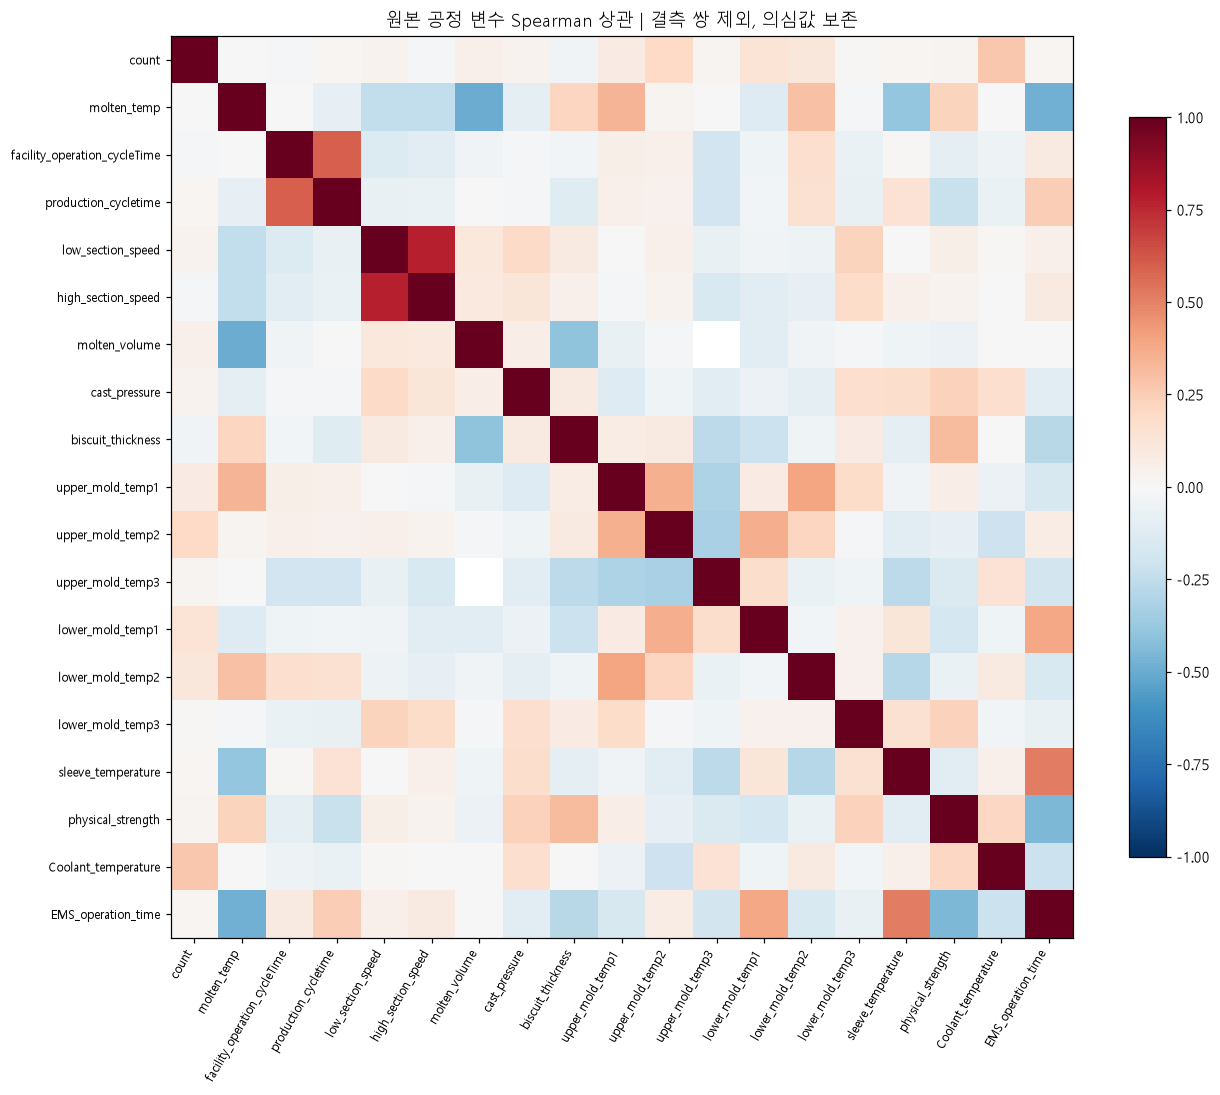

In [9]:
numeric=raw[numeric_cols].replace([np.inf,-np.inf],np.nan)
# 각 쌍의 공통 유효값에서 순위를 다시 계산합니다. scipy 없이 Spearman 계산.
corr=pd.DataFrame(np.nan,index=numeric_cols,columns=numeric_cols)
pair_n=pd.DataFrame(0,index=numeric_cols,columns=numeric_cols)
for i,a in enumerate(numeric_cols):
    for j in range(i,len(numeric_cols)):
        b=numeric_cols[j]
        mask=numeric[a].notna() & numeric[b].notna()
        pair_n.loc[a,b]=pair_n.loc[b,a]=int(mask.sum())
        if mask.sum()>=30 and numeric.loc[mask,a].nunique()>1 and numeric.loc[mask,b].nunique()>1:
            value=numeric.loc[mask,a].rank().corr(numeric.loc[mask,b].rank())
            corr.loc[a,b]=corr.loc[b,a]=value
show_table(corr,"11_spearman.csv")
pair_n.to_csv(TABLE_DIR/"12_pairwise_sample_counts.csv",encoding="utf-8-sig")
fig,ax=plt.subplots(figsize=(12,10))
im=ax.imshow(np.ma.masked_invalid(corr.to_numpy()),cmap="RdBu_r",vmin=-1,vmax=1)
ax.set_xticks(range(len(numeric_cols)),numeric_cols,rotation=60,ha="right",fontsize=8)
ax.set_yticks(range(len(numeric_cols)),numeric_cols,fontsize=8)
ax.set_title("원본 공정 변수 Spearman 상관 | 결측 쌍 제외, 의심값 보존")
fig.colorbar(im,ax=ax,shrink=.8);show_plot(fig,"09_spearman.png")

## 9 압력과 금형 온도의 관계
최대 4,000건을 고정 시드로 단순 무작위 추출한 산점도입니다. 원본의 자연스러운 라벨 비율을 유지하려는 표본이며 클래스 수를 강제로 맞추지 않습니다. 1~99백분위로 표시 범위만 제한하고 표시 밖 건수를 출력합니다.

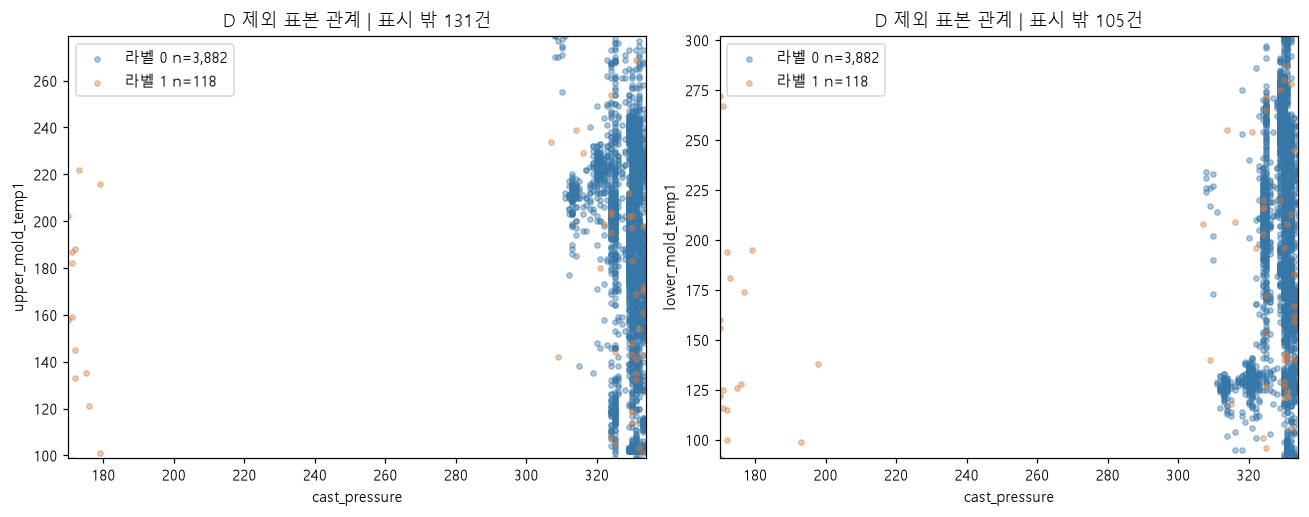

In [10]:
subset=valid.loc[~valid._D].dropna(subset=["cast_pressure","upper_mold_temp1","lower_mold_temp1"])
sample=subset.sample(n=min(SCATTER_SAMPLE,len(subset)),random_state=RANDOM_SEED)
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for ax,temp in zip(axes,["upper_mold_temp1","lower_mold_temp1"]):
    for label,color in [(0,COLORS[0]),(1,COLORS[1])]:
        group=sample.loc[sample._label.eq(label)]
        ax.scatter(group.cast_pressure,group[temp],s=12,alpha=.4,color=color,label=f"라벨 {label} n={len(group):,}")
    xl,xh=subset.cast_pressure.quantile([.01,.99]);yl,yh=subset[temp].quantile([.01,.99])
    ax.set_xlim(xl,xh);ax.set_ylim(yl,yh)
    outside=~(sample.cast_pressure.between(xl,xh)&sample[temp].between(yl,yh))
    ax.set_title(f"D 제외 표본 관계 | 표시 밖 {outside.sum():,}건")
    ax.set_xlabel("cast_pressure");ax.set_ylabel(temp);ax.legend()
show_plot(fig,"10_pressure_temperature.png")

## 10 count 구간별 탐색
count가 실제 생산 순번인지는 미확인입니다. 구간별 비율 차이가 있어도 생산 초기 불량으로 단정하지 않습니다. 구간은 설명을 위한 고정 폭이며 정답에 맞춰 선택하지 않습니다. 표본 수를 함께 확인합니다.

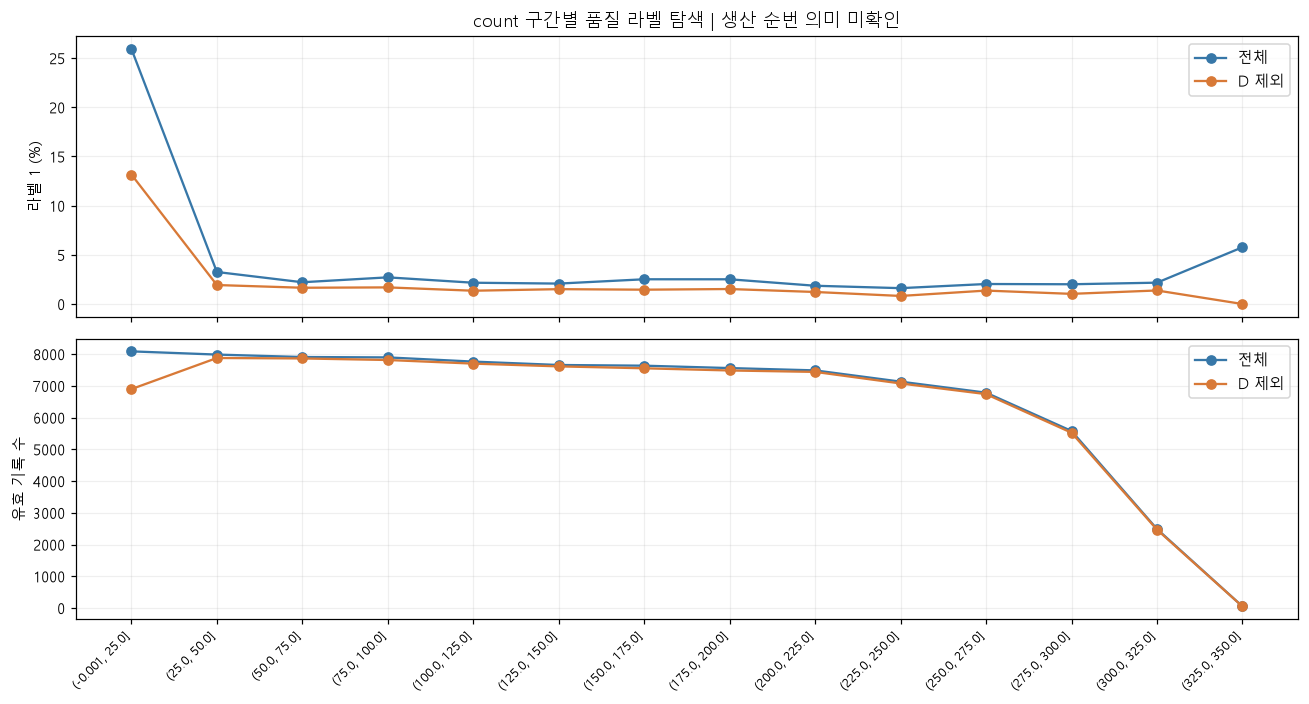

In [11]:
count_view=valid.copy()
edges=np.arange(0,max(350,int(np.ceil(count_view['count'].max()/25)*25))+1,25)
count_view["_count_bin"]=pd.cut(count_view["count"],bins=edges,include_lowest=True)
fig,axes=plt.subplots(2,1,figsize=(12,6.5),sharex=True)
for name,subset,color in [("전체",count_view,COLORS[0]),("D 제외",count_view.loc[~count_view._D],COLORS[1])]:
    group=subset.groupby("_count_bin",observed=False)._label.agg(기록수="size",라벨1비율="mean")
    group.to_csv(TABLE_DIR/f"13_count_{'all' if name=='전체' else 'nonD'}.csv",encoding="utf-8-sig")
    axes[0].plot(np.arange(len(group)),group.라벨1비율*100,marker="o",label=name,color=color)
    axes[1].plot(np.arange(len(group)),group.기록수,marker="o",label=name,color=color)
axes[0].set_title("count 구간별 품질 라벨 탐색 | 생산 순번 의미 미확인")
axes[0].set_ylabel("라벨 1 (%)");axes[1].set_ylabel("유효 기록 수")
axes[1].set_xticks(np.arange(len(group)),group.index.astype(str),rotation=45,ha="right",fontsize=8)
for ax in axes:ax.legend();ax.grid(alpha=.2)
show_plot(fig,"11_count_bins.png")

## 11 특이값과 추가 확인 대상
지정값 빈도와 실제 해당 행을 확인합니다. 이 목록은 의심값의 예시이며 모든 센서 오류를 포괄하지 않습니다. 기록 삭제·대체는 하지 않습니다.

,변수,의심값,건수,전체비율_pct
0,low_section_speed,65535,1,0.001087
1,physical_strength,65535,3,0.003260
2,upper_mold_temp1,1449,1,0.001087
3,upper_mold_temp3,1449,82759,89.940771
4,lower_mold_temp2,1449,4,0.004347
5,lower_mold_temp3,1449,89979,97.787317
6,lower_mold_temp3,65503,1,0.001087
7,sleeve_temperature,1449,57,0.061946
8,Coolant_temperature,1449,9,0.009781


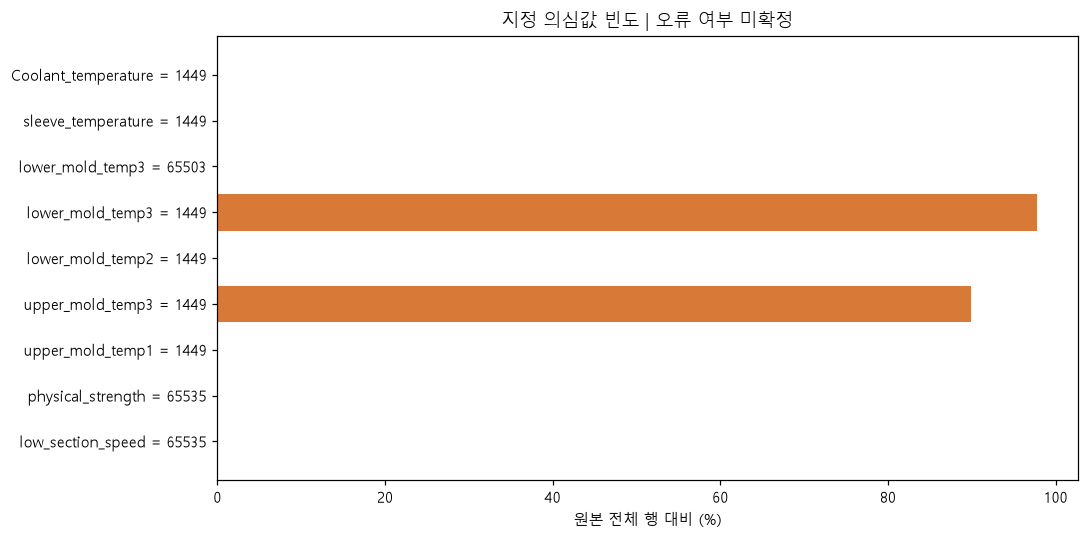

,Unnamed: 0,line,name,mold_name,time,date,count,working,emergency_stop,molten_temp,...,lower_mold_temp3,sleeve_temperature,physical_strength,Coolant_temperature,EMS_operation_time,registration_time,passorfail,tryshot_signal,mold_code,heating_furnace
6000,6000,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-11,22:55:42,74,가동,ON,690.0,...,1449.0,456.0,65535.0,29.0,23,2019-01-11 22:55:42,1.0,NaN,8412,NaN
11811,11811,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-18,23:19:22,5,가동,ON,709.0,...,1449.0,437.0,65535.0,31.0,23,2019-01-18 23:19:22,1.0,NaN,8412,NaN
17598,17598,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-24,07:59:34,1,가동,ON,NaN,...,1449.0,496.0,65535.0,40.0,23,2019-01-24 07:59:34,1.0,NaN,8412,NaN
19327,19327,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-01-25,19:09:09,281,NaN,NaN,722.0,...,NaN,NaN,NaN,NaN,0,2019-01-25 19:09:09,NaN,NaN,8722,NaN
46546,46546,전자교반 3라인 2호기,TM Carrier RH,TM Carrier RH-Semi-Solid DIE-06,2019-02-20,22:02:43,1,정지,ON,729.0,...,1449.0,74.0,3.0,22.0,23,2019-02-20 22:02:43,1.0,D,8722,NaN


EDA 완료: 원본 보존 확인
그래프: C:\Users\KDS-30\Desktop\Projects\05_KAMP\previous_competition\4\outputs\eda\figures
통계표: C:\Users\KDS-30\Desktop\Projects\05_KAMP\previous_competition\4\outputs\eda\tables


In [12]:
suspects={"low_section_speed":[65535],"physical_strength":[65535],"upper_mold_temp1":[1449],"upper_mold_temp3":[1449],"lower_mold_temp2":[1449],"lower_mold_temp3":[1449,65503],"sleeve_temperature":[1449],"Coolant_temperature":[1449]}
records=[]
for col,values in suspects.items():
    for value in values:
        mask=raw[col].eq(value)
        records.append({"변수":col,"의심값":value,"건수":int(mask.sum()),"전체비율_pct":mask.mean()*100})
suspect_table=pd.DataFrame(records)
show_table(suspect_table,"14_suspect_values.csv")
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(suspect_table.변수+" = "+suspect_table.의심값.astype(str),suspect_table.전체비율_pct,color=COLORS[1])
ax.set_xlabel("원본 전체 행 대비 (%)");ax.set_title("지정 의심값 빈도 | 오류 여부 미확정")
show_plot(fig,"12_suspect_values.png")
display(raw.loc[raw.low_section_speed.eq(65535)|raw.physical_strength.eq(65535)|raw[TARGET].isna()])
assert raw.equals(raw_snapshot), "원본 DataFrame이 변경되었습니다."
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash, "원본 파일이 변경되었습니다."
print("EDA 완료: 원본 보존 확인")
print("그래프:",FIG_DIR)
print("통계표:",TABLE_DIR)

## 관찰 결과를 정리할 질문
- D 기록을 포함·제외할 때 월별 라벨 변화가 어떻게 달라지는가?
- 특정 금형 코드에 결측이 집중되는 이유는 무엇인가?
- 전체 범위와 확대 분포에서 각각 보이는 특징은 무엇인가?
- 압력·온도 차이는 월이나 금형 코드의 영향으로도 설명될 수 있는가?
- count 구간별 차이가 실제 시작·재시작과 연결되는가?
- 1449와 65535 등의 값은 어떤 장비 상태에서 기록되었는가?

이 질문에 대한 관찰을 정리한 다음 전처리 규칙을 결정합니다. 이 노트북 자체는 전처리된 학습 데이터나 모델 성능을 생성하지 않습니다.